# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [15]:
# Варіант 1: завантажити CSV з комп’ютера в Colab
from google.colab import files
from io import BytesIO
uploaded = files.upload()
filename = next(name for name in uploaded if name.lower().endswith('.csv'))
df = pd.read_csv(BytesIO(uploaded[filename]))
print('Завантажено:', filename, df.shape)

Saving house_price_regression_dataset.csv to house_price_regression_dataset (1).csv
Завантажено: house_price_regression_dataset (1).csv (1000, 8)


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [16]:
# Варіант 2: Kaggle (альтернатива варіанту 1; виконуйте лише один спосіб)
# !pip -q install kagglehub
# import kagglehub
# from pathlib import Path
# folder = Path(kagglehub.dataset_download('prokshitha/home-value-insights'))
# csv_file = next(folder.rglob('*.csv'))
# df = pd.read_csv(csv_file)
# print('Завантажено:', csv_file, df.shape)

## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [17]:
print(df.head())
print("Розмір:", df.shape)
df.info()

   Square_Footage  Num_Bedrooms  Num_Bathrooms  Year_Built  Lot_Size  \
0            1360             2              1        1981  0.599637   
1            4272             3              3        2016  4.753014   
2            3592             1              2        2016  3.634823   
3             966             1              2        1977  2.730667   
4            4926             2              1        1993  4.699073   

   Garage_Size  Neighborhood_Quality   House_Price  
0            0                     5  2.623829e+05  
1            1                     6  9.852609e+05  
2            0                     9  7.779774e+05  
3            1                     8  2.296989e+05  
4            0                     8  1.041741e+06  
Розмір: (1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage     

### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [18]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [19]:
print(df.isna().sum())

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [20]:
display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [21]:
print(df["Neighborhood_Quality"].value_counts().sort_index())

Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

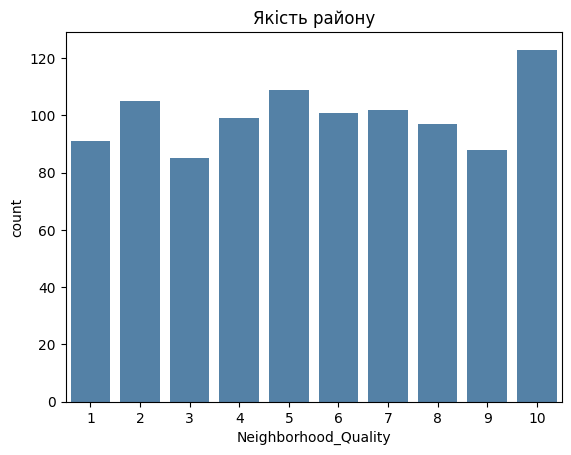

In [22]:
sns.countplot(data=df, x="Neighborhood_Quality", color="steelblue")
plt.title("Якість району")
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [23]:
print(df["Num_Bathrooms"].value_counts().sort_index())

Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

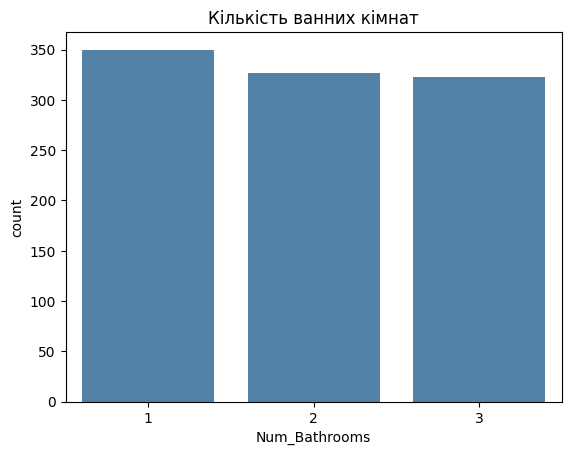

In [24]:
sns.countplot(data=df, x="Num_Bathrooms", color="steelblue")
plt.title("Кількість ванних кімнат")
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

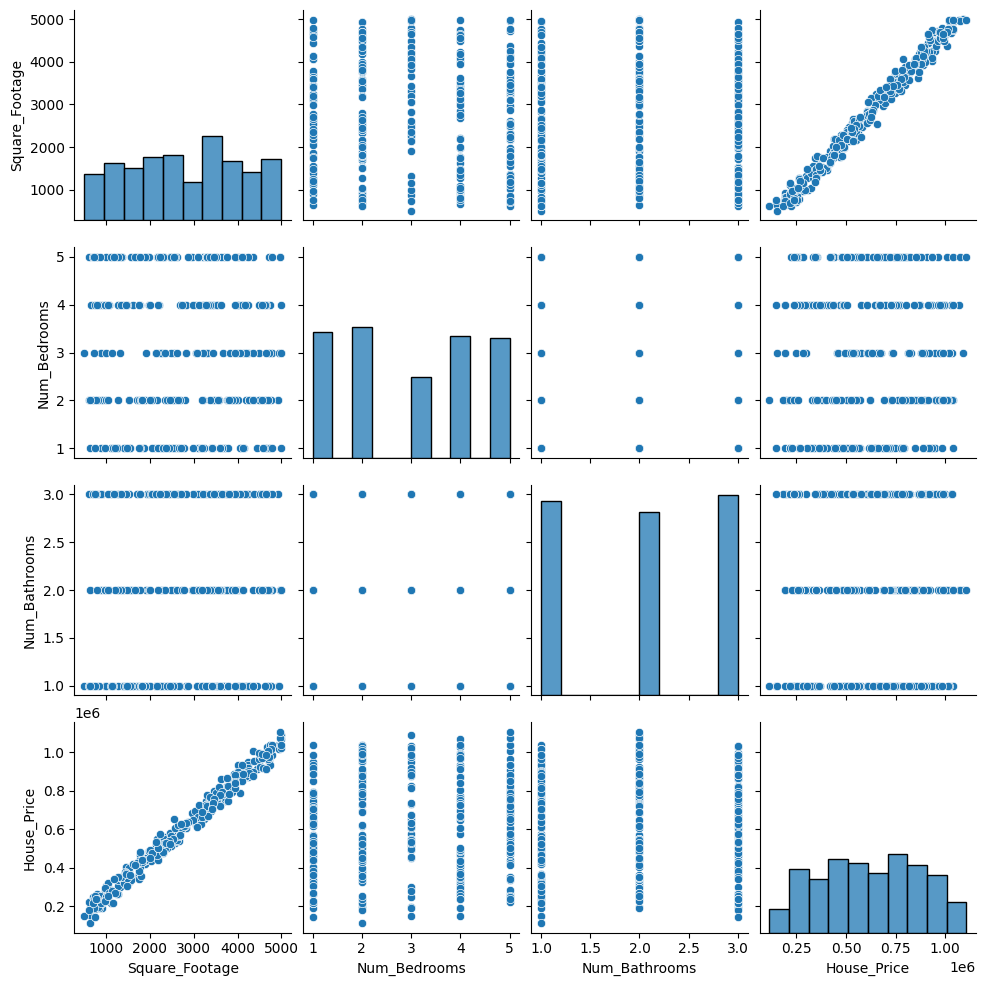

In [25]:
sns.pairplot(
    df[["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "House_Price"]]
    .dropna()
    .sample(
        n=min(300, len(df.dropna(subset=[
            "Square_Footage", "Num_Bedrooms",
            "Num_Bathrooms", "House_Price"
        ]))),
        random_state=42
    )
)

plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

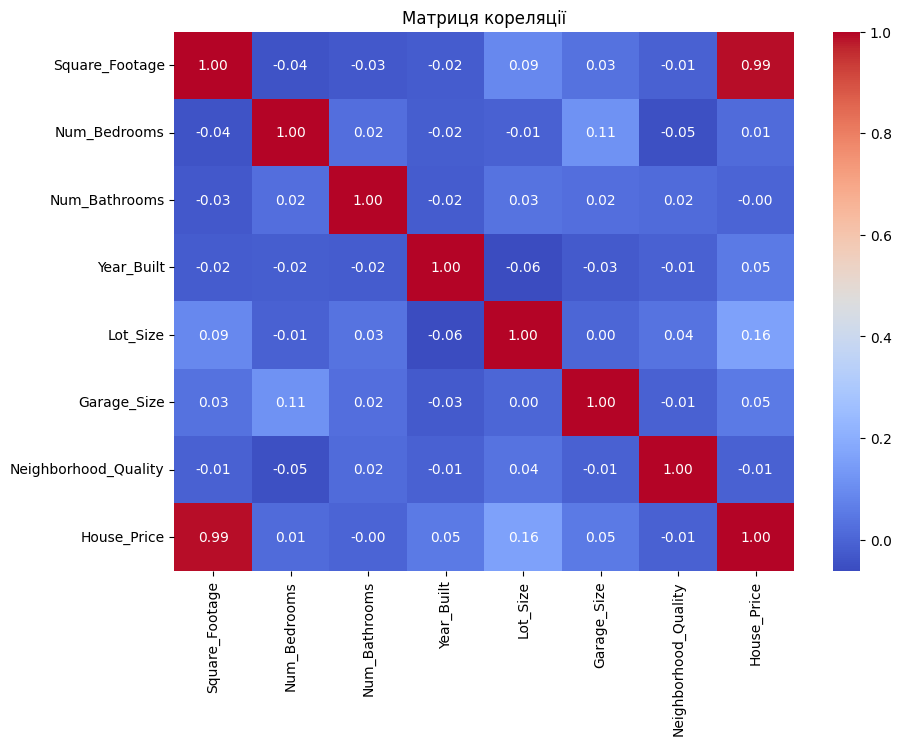

In [26]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Матриця кореляції")
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [27]:
print(corr["House_Price"].sort_values(ascending=False))

House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [28]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [29]:
data = df.drop_duplicates().dropna(subset=["House_Price"]).copy()
X = data.drop(columns="House_Price").select_dtypes(include="number")
y = data["House_Price"]
print("Ознаки:", X.columns.tolist())

Ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [31]:
models = {
    'Linear Regression': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', LinearRegression())]),
    'Ridge': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', Ridge())]),
    'Lasso': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', Lasso(max_iter=10000))]),
    'Random Forest': Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', GradientBoostingRegressor(random_state=42))])
}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [32]:
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({'Модель': name, 'R²': r2_score(y_test, pred),
                    'MAE': mean_absolute_error(y_test, pred),
                    'MSE': mean_squared_error(y_test, pred)})
results_df = pd.DataFrame(results).sort_values('R²', ascending=False)
display(results_df.round(3))

,Модель,R²,MAE,MSE
0,Linear Regression,0.998,8174.584,1.014348e+08
2,Lasso,0.998,8174.748,1.014366e+08
1,Ridge,0.998,8241.587,1.024810e+08
4,Gradient Boosting,0.997,12305.218,2.249656e+08
3,Random Forest,0.994,16114.290,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

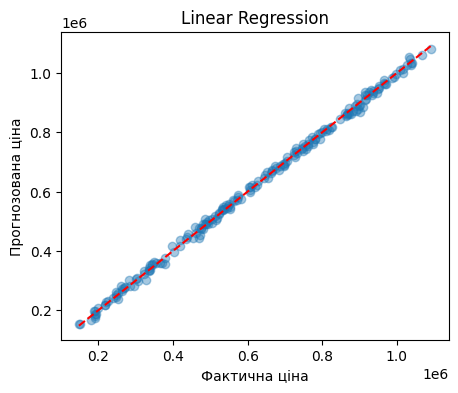

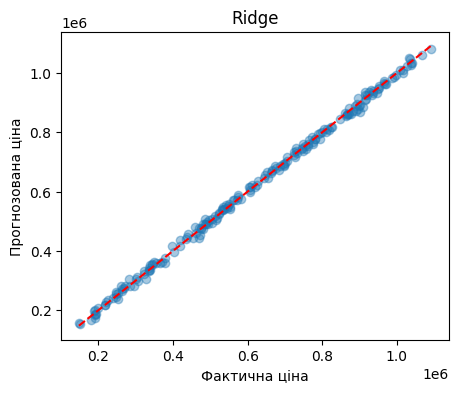

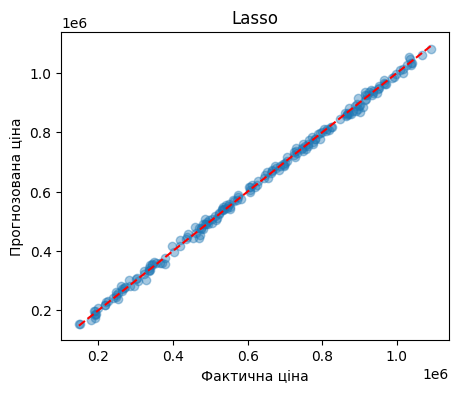

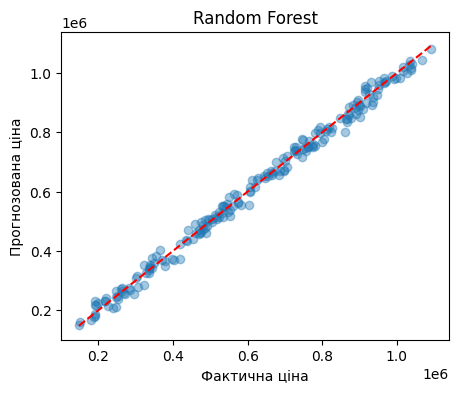

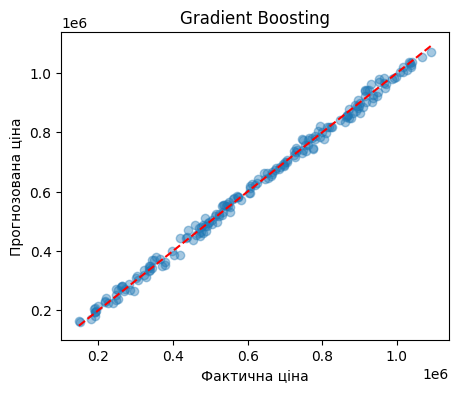

In [33]:
for name, pred in predictions.items():
    plt.figure(figsize=(5, 4))
    plt.scatter(y_test, pred, alpha=0.4)
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())
    plt.plot([low, high], [low, high], 'r--')
    plt.xlabel('Фактична ціна')
    plt.ylabel('Прогнозована ціна')
    plt.title(name)
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [34]:
param_grid = {
    'n_estimators': [50, 100],
    'max_features': ['sqrt', 1.0],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}
search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid, cv=3, scoring='r2', n_jobs=-1
)
X_train_filled = models['Random Forest'].named_steps['imputer'].transform(X_train)
search.fit(X_train_filled, y_train)
print('Найкращі параметри:', search.best_params_)
print('R² на крос-валідації:', round(search.best_score_, 4))

Найкращі параметри: {'max_depth': 10, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}
R² на крос-валідації: 0.9913


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [35]:
best_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(**search.best_params_, random_state=42, n_jobs=-1))
])
best_rf.fit(X_train, y_train)
best_pred = best_rf.predict(X_test)
optimized = {'Модель': 'Random Forest (оптимізована)',
             'R²': r2_score(y_test, best_pred),
             'MAE': mean_absolute_error(y_test, best_pred),
             'MSE': mean_squared_error(y_test, best_pred)}
print(optimized)

{'Модель': 'Random Forest (оптимізована)', 'R²': 0.9938347274193514, 'MAE': 16073.020989525343, 'MSE': 397406424.17357343}


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [36]:
comparison = pd.concat([
    results_df.loc[results_df['Модель'] == 'Random Forest'],
    pd.DataFrame([optimized])
], ignore_index=True)
display(comparison.round(3))

,Модель,R²,MAE,MSE
0,Random Forest,0.994,16114.290,3.941317e+08
1,Random Forest (оптимізована),0.994,16073.021,3.974064e+08


### Завдання 20. Аналіз оптимізації

Висновок формується після запуску коду, щоб він відповідав отриманим метрикам.


In [37]:
base_rf = comparison.iloc[0]
tuned_rf = comparison.iloc[1]
print('Зміна R²:', round(tuned_rf['R²'] - base_rf['R²'], 4))
print('Зміна MAE:', round(tuned_rf['MAE'] - base_rf['MAE'], 2))
print('Зміна MSE:', round(tuned_rf['MSE'] - base_rf['MSE'], 2))
print('Оптимізація покращила R².' if tuned_rf['R²'] > base_rf['R²'] else 'Оптимізація не покращила R² на тестовій вибірці.')


Зміна R²: -0.0001
Зміна MAE: -41.27
Зміна MSE: 3274676.73
Оптимізація не покращила R² на тестовій вибірці.


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [38]:
linear_pred = predictions['Linear Regression']
pred_table = pd.DataFrame({
    'Фактична ціна': y_test.to_numpy(),
    'Прогнозована ціна': linear_pred
})
pred_table['Похибка, %'] = (
    (pred_table['Фактична ціна'] - pred_table['Прогнозована ціна']).abs()
    / pred_table['Фактична ціна'].abs().replace(0, np.nan) * 100
)
display(pred_table.sample(n=min(10, len(pred_table)), random_state=42).round(2))

,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки

За результатами виконання порівнюються п'ять моделей регресії за R², MAE та MSE. Найкраща модель визначається за результатами на тестовій вибірці. Підбір параметрів Random Forest оцінюється окремо; він не гарантує покращення. На точність прогнозу можуть впливати площа, розташування, стан будинку, обсяг даних, пропуски та викиди.


In [39]:
best = results_df.iloc[0]
print('Найкраща базова модель:', best['Модель'])
print('R²:', round(best['R²'], 4))
print('MAE:', round(best['MAE'], 2))
print('MSE:', round(best['MSE'], 2))
print('R² оптимізованого Random Forest:', round(optimized['R²'], 4))


Найкраща базова модель: Linear Regression
R²: 0.9984
MAE: 8174.58
MSE: 101434798.51
R² оптимізованого Random Forest: 0.9938
